In [1]:
MODEL_NAME = "neuralmind/bert-base-portuguese-cased"   # BERTimbau base
HUB_REPO = "suellenlima/bertimbau-sentimento-reviews-ptbr"  # <- troque pelo seu usuário

SEED = 42
MAX_LENGTH = 128
TEST_SIZE = 0.10
VAL_SIZE = 0.10

LEARNING_RATE = 2e-5
EPOCHS = 3
BATCH_SIZE = 32
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1

ID2LABEL = {0: "negativo", 1: "positivo"}
LABEL2ID = {v: k for k, v in ID2LABEL.items()}

OUTPUT_DIR = "checkpoints"
RESULTS_DIR = "resultados"
IMAGES_DIR = "images"

In [2]:
%pip install -q "transformers>=5.0" "datasets>=3.0" "accelerate>=1.0" scikit-learn kagglehub matplotlib

In [3]:
import json
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset, DatasetDict
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, f1_score)
from sklearn.model_selection import train_test_split
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          DataCollatorWithPadding, Trainer, TrainingArguments,
                          set_seed)

set_seed(SEED)  # fixa a aleatoriedade de Python, NumPy e PyTorch
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(IMAGES_DIR, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo: {DEVICE}")
if DEVICE == "cpu":
    print("Atenção: sem GPU o treino fica muito lento. Ative a T4 no menu Runtime.")

Dispositivo: cuda


In [4]:
import kagglehub

try:  # lê a chave do Kaggle dos Secrets do Colab, se existir
    from google.colab import userdata
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
except Exception:
    pass  # fora do Colab ou sem Secrets: o dataset é público e costuma baixar mesmo assim

caminho = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
bruto = pd.read_csv(f"{caminho}/olist_order_reviews_dataset.csv")
print(f"{len(bruto):,} avaliações carregadas")

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
99,224 avaliações carregadas


In [5]:
def limpar_texto(texto: str) -> str:
    """Remove quebras de linha e espaços repetidos."""
    return re.sub(r"\s+", " ", str(texto)).strip()


def nota_para_rotulo(nota: int):
    """1-2 -> 0 (negativo), 4-5 -> 1 (positivo), 3 -> None (descartada)."""
    if nota <= 2:
        return 0
    if nota >= 4:
        return 1
    return None


def preparar(bruto: pd.DataFrame) -> pd.DataFrame:
    df = bruto[["review_comment_message", "review_score"]].dropna()
    df = df.rename(columns={"review_comment_message": "text", "review_score": "score"})
    df["text"] = df["text"].map(limpar_texto)
    df = df[df["text"].str.len() > 0]
    df["label"] = df["score"].map(nota_para_rotulo)
    df = df.dropna(subset=["label"]).astype({"label": int})
    df = df.drop_duplicates(subset="text")
    return df[["text", "label"]].reset_index(drop=True)


# testes rápidos das regras (como um teste unitário)
assert limpar_texto("  chegou\r\nfrio  ") == "chegou frio"
assert [nota_para_rotulo(n) for n in [1, 2, 3, 4, 5]] == [0, 0, None, 1, 1]

dados = preparar(bruto)
print(f"{len(dados):,} avaliações após a preparação")
print(dados["label"].map(ID2LABEL).value_counts(normalize=True).round(3))

32,433 avaliações após a preparação
label
positivo    0.68
negativo    0.32
Name: proportion, dtype: float64


In [6]:
treino, resto = train_test_split(
    dados, test_size=TEST_SIZE + VAL_SIZE, stratify=dados["label"], random_state=SEED)
validacao, teste = train_test_split(
    resto, test_size=TEST_SIZE / (TEST_SIZE + VAL_SIZE), stratify=resto["label"], random_state=SEED)

splits = DatasetDict({
    "train": Dataset.from_pandas(treino, preserve_index=False),
    "validation": Dataset.from_pandas(validacao, preserve_index=False),
    "test": Dataset.from_pandas(teste, preserve_index=False),
})
tamanhos = {nome: len(ds) for nome, ds in splits.items()}
print(tamanhos)

{'train': 25946, 'validation': 3243, 'test': 3244}


In [7]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


def tokenizar(lote):
    return tokenizer(lote["text"], truncation=True, max_length=MAX_LENGTH)


tokenizado = splits.map(tokenizar, batched=True)
print(tokenizer.tokenize("A entrega chegou atrasada e a comida fria."))

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/25946 [00:00<?, ? examples/s]

Map:   0%|          | 0/3243 [00:00<?, ? examples/s]

Map:   0%|          | 0/3244 [00:00<?, ? examples/s]

['A', 'entrega', 'chegou', 'atras', '##ada', 'e', 'a', 'comida', 'fria', '.']


In [8]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(ID2LABEL), id2label=ID2LABEL, label2id=LABEL2ID)


def calcular_metricas(eval_pred):
    logits, rotulos = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "f1_macro": f1_score(rotulos, preds, average="macro"),
        "accuracy": accuracy_score(rotulos, preds),
    }

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

In [9]:
args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    learning_rate=LEARNING_RATE,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    weight_decay=WEIGHT_DECAY,
    warmup_steps=WARMUP_RATIO,  # valor entre 0 e 1 = fração dos passos de treino
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    fp16=torch.cuda.is_available(),
    logging_steps=50,
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=tokenizado["train"],
    eval_dataset=tokenizado["validation"],
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=calcular_metricas,
)

trainer.train()
print("Validação (melhor época):", trainer.evaluate())

Epoch,Training Loss,Validation Loss,F1 Macro,Accuracy
1,0.171709,0.162083,0.928771,0.937712
2,0.118518,0.166526,0.933364,0.940796
3,0.088661,0.192962,0.930794,0.938945


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,F1 Macro,Accuracy
0.088661,0.166526,3,0.933364,0.940796


Validação (melhor época): {'eval_loss': 0.16652563214302063, 'eval_f1_macro': 0.933364154723378, 'eval_accuracy': 0.940795559666975}


In [10]:
saida = trainer.predict(tokenizado["test"])
probs = torch.softmax(torch.tensor(saida.predictions), dim=-1).numpy()
y_pred = probs.argmax(axis=-1)
y_true = saida.label_ids

metricas_teste = {
    "f1_macro": round(float(f1_score(y_true, y_pred, average="macro")), 4),
    "accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
    "n_test": int(len(y_true)),
}
print(metricas_teste)
print(classification_report(y_true, y_pred, target_names=list(ID2LABEL.values()), digits=3))

with open(f"{RESULTS_DIR}/metricas_teste.json", "w") as f:
    json.dump({"metricas": metricas_teste, "tamanhos": tamanhos}, f, indent=2)

{'f1_macro': 0.933, 'accuracy': 0.9408, 'n_test': 3244}
              precision    recall  f1-score   support

    negativo      0.885     0.936     0.910      1039
    positivo      0.969     0.943     0.956      2205

    accuracy                          0.941      3244
   macro avg      0.927     0.940     0.933      3244
weighted avg      0.942     0.941     0.941      3244



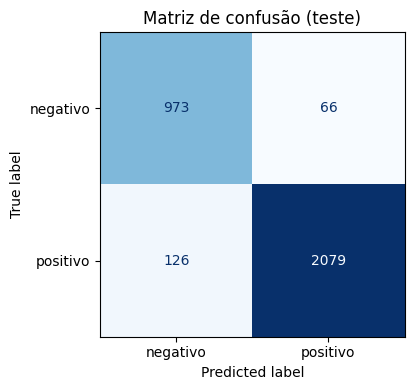

In [11]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, display_labels=list(ID2LABEL.values()), cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Matriz de confusão (teste)")
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/matriz_confusao.png", dpi=150)
plt.show()

In [12]:
analise = teste.reset_index(drop=True).copy()
analise["pred"] = y_pred
analise["confianca"] = probs.max(axis=-1)
analise["real"] = analise["label"].map(ID2LABEL)
analise["previsto"] = analise["pred"].map(ID2LABEL)

erros = analise[analise["label"] != analise["pred"]].sort_values("confianca", ascending=False)
print(f"{len(erros)} erros em {len(analise)} exemplos de teste ({len(erros) / len(analise):.1%})")
erros[["text", "real", "previsto", "confianca"]].head(20)

192 erros em 3244 exemplos de teste (5.9%)


,text,real,previsto,confianca
1380,"Boneca linda!!! e a entrega no prazo , muito s...",negativo,positivo,0.997594
110,deu tudo certo gostei,negativo,positivo,0.996901
2578,produto de ma qualidade,negativo,positivo,0.996176
829,Loja razuavel,negativo,positivo,0.995914
2852,recomendo demais,negativo,positivo,0.995417
1840,"Bom produto, recomendo o vendedor. Mais nada p...",negativo,positivo,0.995390
323,Produto otimo so demorou chegar...,negativo,positivo,0.994780
466,"Foi entregue na data,só acho que a taxa de ent...",negativo,positivo,0.993512
2716,o produto era exatamente o que eu precisasa,negativo,positivo,0.992496
2681,"Relógio muuuuuuito pequeno, ainda bem que sou ...",negativo,positivo,0.991015


In [13]:
erros[["text", "real", "previsto", "confianca"]].to_csv(f"{RESULTS_DIR}/erros_teste.csv", index=False)

In [14]:
for _, linha in erros.head(20).iterrows():
    print(f"[gabarito: {linha['real']} | modelo: {linha['previsto']} | {linha['confianca']:.2f}]")
    print("   ", linha["text"], "\n")

[gabarito: negativo | modelo: positivo | 1.00]
    Boneca linda!!! e a entrega no prazo , muito satisfeita . 

[gabarito: negativo | modelo: positivo | 1.00]
    deu tudo certo gostei 

[gabarito: negativo | modelo: positivo | 1.00]
    produto de ma qualidade 

[gabarito: negativo | modelo: positivo | 1.00]
    Loja razuavel 

[gabarito: negativo | modelo: positivo | 1.00]
    recomendo demais 

[gabarito: negativo | modelo: positivo | 1.00]
    Bom produto, recomendo o vendedor. Mais nada pra comentar do produto e do vendedor também. 

[gabarito: negativo | modelo: positivo | 0.99]
    Produto otimo so demorou chegar... 

[gabarito: negativo | modelo: positivo | 0.99]
    Foi entregue na data,só acho que a taxa de entrega poderia ser mais em conta. 

[gabarito: negativo | modelo: positivo | 0.99]
    o produto era exatamente o que eu precisasa 

[gabarito: negativo | modelo: positivo | 0.99]
    Relógio muuuuuuito pequeno, ainda bem que sou magra . Ficou legal 

[gabarito: negativo |

In [15]:
from huggingface_hub import HfApi, login

try:
    from google.colab import userdata
    login(token=userdata.get("HF_TOKEN"))
except ImportError:
    login()  # fora do Colab: pede o token

In [21]:
MODEL_CARD = f"""---
language: pt
license: mit
base_model: {MODEL_NAME}
pipeline_tag: text-classification
tags:
  - sentiment-analysis
  - portuguese
  - bertimbau
metrics:
  - f1
  - accuracy
---

# BERTimbau: sentimento de avaliações de compra (pt-BR)

Classifica avaliações de compra em português como **positivo** ou **negativo**.
Fine-tuning do [BERTimbau base]({"https://huggingface.co/" + MODEL_NAME}) com avaliações públicas da Olist.

## Como usar

```python
from transformers import pipeline

clf = pipeline("text-classification", model="{HUB_REPO}")
clf("A entrega chegou atrasada e a comida fria.")
```

## Dados

- Fonte: [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce).
- Rótulos fracos pela nota: 1-2 negativo, 4-5 positivo; nota 3 descartada.
- Duplicatas removidas; divisão estratificada 80/10/10 (seed {SEED}).
- Tamanhos: treino {tamanhos['train']:,}, validação {tamanhos['validation']:,}, teste {tamanhos['test']:,}.

## Treino

learning rate {LEARNING_RATE}, {EPOCHS} épocas, batch {BATCH_SIZE}, max_length {MAX_LENGTH},
warmup {WARMUP_RATIO}, weight decay {WEIGHT_DECAY}; melhor época escolhida pela F1 macro de validação.

## Resultados (conjunto de teste)

| Métrica | Valor |
|---|---|
| F1 macro | {metricas_teste['f1_macro']:.3f} |
| Acurácia | {metricas_teste['accuracy']:.3f} |

## Limitações

- Treinado em avaliações de **e-commerce**, não de restaurantes ou delivery de comida.
- Os rótulos vêm da nota, então há ruído (nota alta com texto negativo e vice-versa).
- Tem dificuldade com **ironia** ("parabéns pela demora") e textos mistos.
- Não classifica sentimento neutro.
- Não deve ser usado para decisões automáticas sobre pessoas sem revisão humana.
"""

with open(f"{RESULTS_DIR}/MODEL_CARD.md", "w", encoding="utf-8") as f:
    f.write(MODEL_CARD)

trainer.model.push_to_hub(HUB_REPO, commit_message="Modelo de sentimento treinado")
tokenizer.push_to_hub(HUB_REPO)
HfApi().upload_file(path_or_fileobj=f"{RESULTS_DIR}/MODEL_CARD.md", path_in_repo="README.md",
                    repo_id=HUB_REPO, commit_message="Model card")
print(f"Publicado: https://huggingface.co/{HUB_REPO}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...jkvc2z7/model.safetensors:   0%|          |  556kB /  436MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Publicado: https://huggingface.co/suellenlima/bertimbau-sentimento-reviews-ptbr


In [22]:
from transformers import pipeline

clf = pipeline("text-classification", model=HUB_REPO, device=0 if DEVICE == "cuda" else -1)
for frase in ["Entrega rápida, comida quentinha!",
              "Pedido veio errado e frio.",
              "Parabéns pela demora."]:
    print(frase, "->", clf(frase)[0])

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/380 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/678k [00:00<?, ?B/s]

Entrega rápida, comida quentinha! -> {'label': 'positivo', 'score': 0.9976423382759094}
Pedido veio errado e frio. -> {'label': 'negativo', 'score': 0.9748509526252747}
Parabéns pela demora. -> {'label': 'negativo', 'score': 0.8924359679222107}


In [23]:
print(f"""| Métrica (teste) | Valor |
|---|---|
| F1 macro | {metricas_teste['f1_macro']:.3f} |
| Acurácia | {metricas_teste['accuracy']:.3f} |
| Exemplos de teste | {metricas_teste['n_test']:,} |""")

| Métrica (teste) | Valor |
|---|---|
| F1 macro | 0.933 |
| Acurácia | 0.941 |
| Exemplos de teste | 3,244 |
